In [3]:
import pandas, sklearn, xgboost, shap
print("All good")

All good


In [4]:
import pandas as pd
import numpy as np
from pathlib import Path

files = sorted(Path("../data/raw").glob("*.csv"))
print(len(files), "files found")

dfs = []
for f in files:
    df = pd.read_csv(f, encoding="latin1", low_memory=False)
    df.columns = df.columns.str.strip()
    for c in df.select_dtypes("float64").columns:
        df[c] = df[c].astype("float32")
    for c in df.select_dtypes("int64").columns:
        df[c] = df[c].astype("int32")
    dfs.append(df)
    print(f.name, df.shape)

data = pd.concat(dfs, ignore_index=True)
del dfs
print("Total:", data.shape)

8 files found
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv (225745, 79)
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv (286467, 79)
Friday-WorkingHours-Morning.pcap_ISCX.csv (191033, 79)
Monday-WorkingHours.pcap_ISCX.csv (529918, 79)
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv (288602, 79)
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv (170366, 79)
Tuesday-WorkingHours.pcap_ISCX.csv (445909, 79)
Wednesday-workingHours.pcap_ISCX.csv (692703, 79)
Total: (2830743, 79)


In [5]:
print(data["Label"].value_counts())

Label
BENIGN                          2273097
DoS Hulk                         231073
PortScan                         158930
DDoS                             128027
DoS GoldenEye                     10293
FTP-Patator                        7938
SSH-Patator                        5897
DoS slowloris                      5796
DoS Slowhttptest                   5499
Bot                                1966
Web Attack ï¿½ Brute Force         1507
Web Attack ï¿½ XSS                  652
Infiltration                         36
Web Attack ï¿½ Sql Injection         21
Heartbleed                           11
Name: count, dtype: int64


In [6]:
num = data.select_dtypes(include=np.number)
print("Infinite values:", np.isinf(num).sum().sum())
print("Missing values:", data.isna().sum().sum())
print("Duplicate rows:", data.duplicated().sum())

Infinite values: 4376
Missing values: 1358
Duplicate rows: 330995


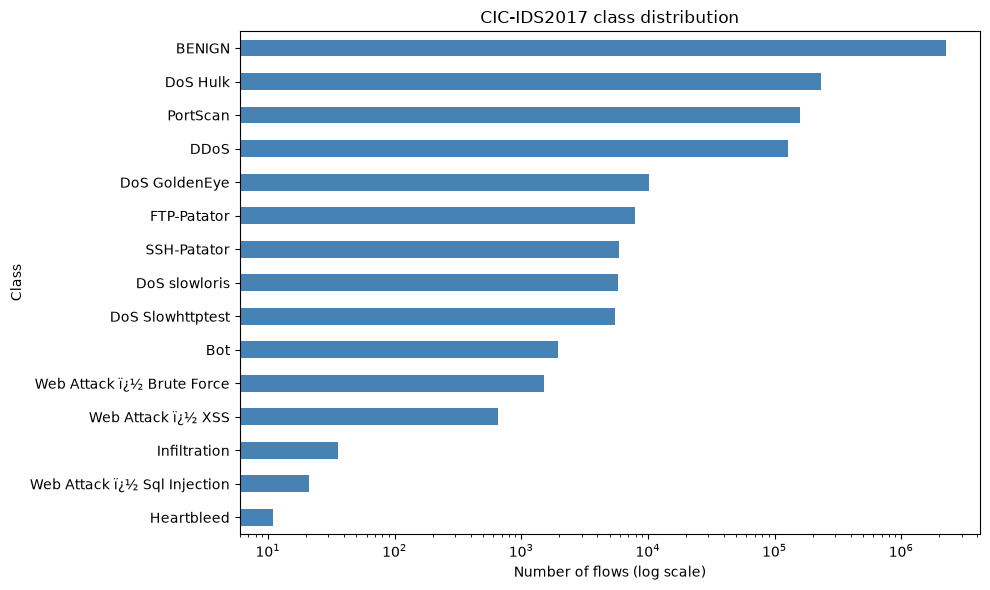

In [7]:
import matplotlib.pyplot as plt

Path("../results/figures").mkdir(parents=True, exist_ok=True)

counts = data["Label"].value_counts()
plt.figure(figsize=(10, 6))
counts.plot(kind="barh", color="steelblue")
plt.xscale("log")
plt.xlabel("Number of flows (log scale)")
plt.ylabel("Class")
plt.title("CIC-IDS2017 class distribution")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("../results/figures/class_distribution.png", dpi=150)
plt.show()

In [8]:
MAX_PER_CLASS = 60000
parts = []
for label, g in data.groupby("Label"):
    parts.append(g.sample(n=min(len(g), MAX_PER_CLASS), random_state=42))
sampled = pd.concat(parts, ignore_index=True)

print(sampled["Label"].value_counts())
print("Sampled shape:", sampled.shape)

Path("../data/processed").mkdir(parents=True, exist_ok=True)
sampled.to_parquet("../data/processed/sampled_raw.parquet")

Label
BENIGN                          60000
DDoS                            60000
DoS Hulk                        60000
PortScan                        60000
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack ï¿½ Brute Force       1507
Web Attack ï¿½ XSS                652
Infiltration                       36
Web Attack ï¿½ Sql Injection       21
Heartbleed                         11
Name: count, dtype: int64
Sampled shape: (279616, 79)
